# Importing and Querying Data with PostgreSQL (Northwind Database)

Describtion of the Northwind Database: https://en.wikiversity.org/wiki/Database_Examples/Northwind 

Example SQL-Queries based on the Northwind Database: https://www.w3schools.com/sql/default.asp

SQL Tutorials: https://www.youtube.com/watch?v=zpnHsWOy0RY&list=PLP9IO4UYNF0UQkBXlTMSw0CYsxv-GDkkI

## Frequently used SQL clauses (for in-depth learning)

<div>
  <style>
    .sql-keyword {
      color: white;
    }
  </style>
  <span class="sql-keyword">SELECT</span><br>
  <span class="sql-keyword">SELECT DISTINCT</span><br>
  <span class="sql-keyword">FROM</span><br>
  <span class="sql-keyword">WHERE</span><br>
  <span class="sql-keyword">AND</span><br>
  <span class="sql-keyword">LIKE</span><br>
  <span class="sql-keyword">GROUP BY</span><br>
  <span class="sql-keyword">HAVING</span><br>
  <span class="sql-keyword">ORDER BY</span><br>
  <span class="sql-keyword">FULL JOIN</span><br>
  <span class="sql-keyword">INNER JOIN</span><br>
  <span class="sql-keyword">LEFT JOIN</span><br>
  <span class="sql-keyword">RIGHT JOIN</span><br>
  <span class="sql-keyword">ON</span><br>
  <span class="sql-keyword">LIMIT</span><br>
  <span class="sql-keyword">AS</span><br>
  <span class="sql-keyword">AVG</span><br>
  <span class="sql-keyword">COUNT</span><br>
  <span class="sql-keyword">MIN</span><br>
  <span class="sql-keyword">MAX</span><br>
  <span class="sql-keyword">SUM</span><br>
  <span class="sql-keyword">BETWEEN</span><br>
  <span class="sql-keyword">IN</span><br>
  <span class="sql-keyword">IS NULL</span><br>
  <span class="sql-keyword">IS NOT NULL</span><br> 
  <span class="sql-keyword">ROUND</span><br> 
  <span class="sql-keyword">CAST</span><br>
  <span class="sql-keyword">NUMERIC</span><br>
  <span class="sql-keyword">INTEGER</span>  
</div>

## Libraries and Settings

In [132]:
# Libraries
import os
import pandas as pd
from sqlalchemy import create_engine, text
import matplotlib.pyplot as plt

# Settings
import warnings
warnings.filterwarnings("ignore")

# Dark background style for all graphics 
plt.style.use('dark_background')

# Current working directory
print(os.getcwd())

/workspaces/python_postgresql_pgadmin


## Read data from .csv files to separate data frames 

In [133]:
# Define path to data
path='Data/'

# Read data from .csv files.
df_categories=pd.read_csv('Data/Categories.csv', sep=',')
df_customers=pd.read_csv('Data/Customers.csv', sep=',')
df_employees=pd.read_csv('Data/Employees.csv', sep=',')
df_orderdetails=pd.read_csv('Data/OrderDetails.csv', sep=',')
df_orders=pd.read_csv('Data/Orders.csv', sep=',')
df_products=pd.read_csv('Data/Products.csv', sep=',')
df_shippers=pd.read_csv('Data/Shippers.csv', sep=',')
df_suppliers=pd.read_csv('Data/Suppliers.csv', sep=',')

# Change column names to lowercase
df_products.columns=df_products.columns.str.lower()
df_categories.columns=df_categories.columns.str.lower()
df_customers.columns=df_customers.columns.str.lower()
df_employees.columns=df_employees.columns.str.lower()
df_orderdetails.columns=df_orderdetails.columns.str.lower()
df_orders.columns=df_orders.columns.str.lower()
df_shippers.columns=df_shippers.columns.str.lower()
df_suppliers.columns=df_suppliers.columns.str.lower()

# Check dimensions of DataFramesy
print("Customers:",df_customers.shape)
print("Suppliers:",df_suppliers.shape)
print("Shippers:",df_shippers.shape)
print("Orders:",df_orders.shape)
print("OrderDetails:",df_orderdetails.shape)
print("Employees:",df_employees.shape)
print("Categories:",df_categories.shape)
print("Products:",df_products.shape)


Customers: (91, 7)
Suppliers: (29, 8)
Shippers: (3, 3)
Orders: (196, 5)
OrderDetails: (518, 4)
Employees: (10, 6)
Categories: (8, 3)
Products: (77, 6)


## Create database connection

In [134]:
# Set up database connection
user = "pgadmin"
password = "geheim"
host = "localhost"
port = "5432"
database = "northwind"

# Create Connection URL
db_connection_url = "postgresql://" + user + ":" + password +\
                    "@" + host + ":" + port + "/" + database

# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Test database connection
with engine.connect() as connection:
    result = connection.execute(text('SELECT current_database()'))
    print(result.fetchone())

# Dispose the engine
engine.dispose()

('northwind',)


## Write data frames to database tables

In [135]:
# Create SQLAlchemy Engine
engine=create_engine(db_connection_url)

# Drop tables if it exist
with engine.connect() as connection:
    connection.execute(text("DROP TABLE IF EXISTS public.categories CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.customers CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.employees CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.orderdetails CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.orders CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.products CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.shippers CASCADE;"))
    connection.execute(text("DROP TABLE IF EXISTS public.suppliers CASCADE;"))
    connection.commit()


# Write DataFrames to database
df_categories.to_sql('categories', engine)
df_customers.to_sql('customers', engine)
df_employees.to_sql('employees', engine)
df_orderdetails.to_sql('orderdetails', engine)
df_orders.to_sql('orders', engine)
df_products.to_sql('products', engine)
df_shippers.to_sql('shippers', engine)
df_suppliers.to_sql('suppliers', engine)

# Dispose the engine
engine.dispose()

## List tables in the database

In [136]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Open a connection
with engine.connect() as connection:

    # Execute the query
    result = connection.execute(text("""SELECT table_name
                                        FROM information_schema.tables
                                        WHERE table_schema = 'public'"""))
    
    # Fetch and print the results
    for row in result:
        print(row[0])

# Dispose the engine
engine.dispose()

categories
customers
employees
orderdetails
orders
products
shippers
suppliers


## Create a SQL query to retrieve product information from a database.

In [137]:
# Create SQLAlchemy Engine
engine = create_engine(db_connection_url)

# Write data to table für die nachfolgende Aufgabe - in diesem Fall product prices
df_sub = pd.read_sql_query('''SELECT Products.ProductID, Products.ProductName, Products.Price, Categories.categoryname
                                FROM Products
                                INNER JOIN Categories ON Products.CategoryID = Categories.CategoryID --hätte ein Produkt keine Kategorie, wären im Vergleich zu vorhin wo bei DataFrame dimensions für product (77,6) angezeigt wurde neu nun weniger -> inner Join = nur wenn ein Product auch eine Kategorie hat, wird es angezeigt.
                                ORDER BY Products.ProductID;''',
                           con=engine)

# Dispose the engine
engine.dispose()

# Show the data
df_sub

,productid,productname,price,categoryname
0,1,Chais,18.00,Beverages
1,2,Chang,19.00,Beverages
2,3,Aniseed Syrup,10.00,Condiments
3,4,Chef Anton's Cajun Seasoning,22.00,Condiments
4,5,Chef Anton's Gumbo Mix,21.35,Condiments
...,...,...,...,...
72,73,Röd Kaviar,15.00,Seafood
73,74,Longlife Tofu,10.00,Produce
74,75,Rhönbräu Klosterbier,7.75,Beverages
75,76,Lakkalikööri,18.00,Beverages


## Plot product prices

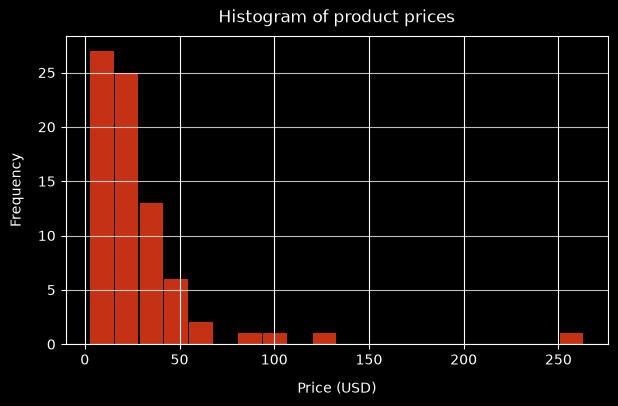

In [138]:
# Plot Histogram
fig = plt.figure( figsize=(7,4))
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14, rotation=0)
n, bins, patches = plt.hist(x=df_sub['price'], 
                            bins=20, 
                            color='#C53115',
                            alpha=1.00, 
                            rwidth=0.95
                   )
plt.grid(True)
plt.ticklabel_format(style='plain')
plt.grid(axis='y', alpha=0.75)

# Set labels
plt.xlabel('Price (USD)', fontsize=10, labelpad=10)
plt.ylabel('Frequency', fontsize=10, labelpad=10)
plt.title('Histogram of product prices', fontsize=12, pad=10)

# Set fontsize of tick labels
plt.xticks(fontsize = 10)
plt.yticks(fontsize = 10)

plt.show()

Nach rechts werden die Balken immer kleiner. Man nennt das eine rechtsschiefe Verteilung: viele günstige, wenige teure Produkte.
Ganz rechts, bei etwa 260 USD, steht ein einzelnes Produkt weit weg von allen anderen. Das ist ein Ausreisser.

Beantwortung der Questions:

1. What are the details of all customers whose country is 'Spain'?

In [139]:
engine=create_engine(db_connection_url)

df_q1=pd.read_sql_query('''SELECT *
FROM customers
WHERE country = 'Spain'
''', con=engine)

engine.dispose()
df_q1

,index,customerid,customername,contactname,address,city,postalcode,country
0,7,8,Bólido Comidas preparadas,Martín Sommer,"C/ Araquil, 67",Madrid,28023,Spain
1,21,22,FISSA Fabrica Inter. Salchichas S.A.,Diego Roel,"C/ Moralzarzal, 86",Madrid,28034,Spain
2,28,29,Galería del gastrónomo,Eduardo Saavedra,"Rambla de Cataluña, 23",Barcelona,8022,Spain
3,29,30,Godos Cocina Típica,José Pedro Freyre,"C/ Romero, 33",Sevilla,41101,Spain
4,68,69,Romero y tomillo,Alejandra Camino,"Gran Vía, 1",Madrid,28001,Spain


2. What are the distinct cities of customers from Germany with a city containing the letter 'B'?


In [140]:
engine=create_engine(db_connection_url)

df_q2=pd.read_sql_query('''SELECT DISTINCT city
FROM customers
WHERE country = 'Germany' AND city LIKE '%%B%%'
''', con=engine)

engine.dispose()
df_q2

,city
0,Berlin
1,Brandenburg


3. What are the number of orders placed by each customer? Sort the result by the number of orders in descending order.


In [141]:
engine=create_engine(db_connection_url)

df_q3=pd.read_sql_query('''SELECT customerid, COUNT(OrderID) --COUNT(*) zählt alle Zeilen (auch die die leer sind), COUNT(orderid) nur Zeilen mit Wert (nicht NULL); hier gleich aber besser COUNT(orderid) zu nehmen, da wir ja die Anzahl der Bestellungen pro Kunde haben wollen und nicht die Anzahl der Kunden (die ja immer 1 ist)
FROM Orders
GROUP BY customerid 
ORDER BY COUNT(*) DESC 
''', con=engine)

engine.dispose()
df_q3

,customerid,count
0,20,10
1,65,7
2,63,7
3,87,7
4,37,6
...,...,...
69,70,1
70,90,1
71,31,1
72,27,1


4. What are the customers who have placed more than 3 orders?


In [142]:
engine=create_engine(db_connection_url)

df_q4=pd.read_sql_query('''SELECT customerid, COUNT(orderid) as CustomerOrderCount
FROM orders
GROUP BY customerid
having COUNT(orderid) > 3
ORDER BY CustomerOrderCount DESC
''', con=engine)

engine.dispose()
df_q4

,customerid,customerordercount
0,20,10
1,65,7
2,63,7
3,87,7
4,37,6
5,75,6
6,51,5
7,46,5
8,41,5
9,55,4


In [143]:
5. What are the top 5 most expensive products? Round the price to 2 decimal places.


SyntaxError: invalid syntax (4134715661.py, line 1)

In [ ]:
engine=create_engine(db_connection_url)

df_q5=pd.read_sql_query('''SELECT productname, ROUND(CAST(price AS NUMERIC),2) AS Price
FROM Products
ORDER BY price DESC
LIMIT 5
''', con=engine)

engine.dispose()
df_q5

,productname,price
0,Côte de Blaye,263.50
1,Thüringer Rostbratwurst,123.79
2,Mishi Kobe Niku,97.00
3,Sir Rodney's Marmalade,81.00
4,Carnarvon Tigers,62.50


6. What are the order details (ProductID, Quantity) for customers from France?

In [ ]:
engine=create_engine(db_connection_url)

df_q6=pd.read_sql_query('''SELECT productid, quantity
FROM orderdetails od
JOIN orders o ON od.orderid = o.orderid
JOIN customers c ON o.customerid = c.customerid
WHERE c.country = 'France'
''', con=engine)

engine.dispose()
df_q6

,productid,quantity
0,22,6
1,57,15
2,65,20
3,17,30
4,70,20
5,71,20
6,72,7
7,56,4
8,39,60
9,72,20


7. Area there products without a category assigned?


In [ ]:
engine=create_engine(db_connection_url)

df_q7=pd.read_sql_query('''SELECT productname
FROM products
WHERE categoryid IS NULL
''', con=engine)

engine.dispose()
df_q7

,index,productid,productname,supplierid,categoryid,unit,price


8. What are all orders and their employees?


In [ ]:
engine=create_engine(db_connection_url)

df_q8=pd.read_sql_query('''SELECT o.orderid, e.employeeid, e.FirstName, e.LastName
FROM orders o
JOIN employees e ON o.employeeid = e.employeeid
''', con=engine)

engine.dispose()
df_q8

,orderid,employeeid,firstname,lastname
0,10248,5,Steven,Buchanan
1,10249,6,Michael,Suyama
2,10250,4,Margaret,Peacock
3,10251,3,Janet,Leverling
4,10252,4,Margaret,Peacock
...,...,...,...,...
191,10439,6,Michael,Suyama
192,10440,4,Margaret,Peacock
193,10441,3,Janet,Leverling
194,10442,3,Janet,Leverling


9. What is the average, minimum, and maximum price of products? Round the values to 2 decimal places.

In [ ]:
engine=create_engine(db_connection_url)

df_q9=pd.read_sql_query('''SELECT 
ROUND(CAST(AVG(price) AS NUMERIC),2) AS average_price,
 ROUND(CAST(MIN(price) AS NUMERIC),2) AS minimum_price,
 ROUND(CAST(MAX(price) AS NUMERIC),2) AS maximum_price
FROM products
''', con=engine)

engine.dispose()
df_q9

,average_price,minimum_price,maximum_price
0,28.87,2.5,263.5


10. What are the products with prices between 10 and 50? Round the price to 2 decimal places and sort the result by price in descending order.


In [ ]:
engine=create_engine(db_connection_url)

df_q10=pd.read_sql_query('''SELECT productid, productname, ROUND(CAST((price) AS NUMERIC),2) AS rounded_price
FROM products
WHERE price BETWEEN 10 AND 50
ORDER BY price DESC
''', con=engine)

engine.dispose()
df_q10

,productid,productname,rounded_price
0,62,Tarte au sucre,49.30
1,43,Ipoh Coffee,46.00
2,28,Rössle Sauerkraut,45.60
3,27,Schoggi Schokolade,43.90
4,63,Vegie-spread,43.90
5,8,Northwoods Cranberry Sauce,40.00
6,17,Alice Mutton,39.00
7,56,Gnocchi di nonna Alice,38.00
8,12,Queso Manchego La Pastora,38.00
9,69,Gudbrandsdalsost,36.00


11. What are the shippers and the total number of orders shipped by each shipper, including those with no orders?

In [ ]:
engine=create_engine(db_connection_url)

df_q11=pd.read_sql_query('''SELECT s.shipperid, s.shippername, COUNT(o.orderid) AS total_no_orders
FROM shippers s
LEFT JOIN Orders o ON s.shipperid=o.shipperid
GROUP BY s.shipperid , s.shippername
''', con=engine)

engine.dispose()
df_q11

,shipperid,shippername,total_no_orders
0,2,United Package,74
1,3,Federal Shipping,68
2,1,Speedy Express,54


12. What are the employees who have processed > 5 orders? Sort the result by the number of orders in descending order.

In [ ]:
engine=create_engine(db_connection_url)

df_q12f=pd.read_sql_query('''SELECT DISTINCT o.employeeID, E.lastname, e.firstname, o.orderid
FROM employees e
JOIN Orders o ON e.employeeID = o.employeeid
GROUP BY o.employeeID, E.lastname, e.firstname, o.orderid
HAVING o.employeeID > 5
ORDER BY o.employeeID DESC
''', con=engine)

engine.dispose()
df_q12f

#stimmt nicht, weil das nur anschaut, welcher Mitarbeiter eine employeeid > 5 hat, also dessen nummer nicht die anzahl.
# ANZAHL = Count!! dh hier wäre es gewesen COUNT(o.orderid) as TotalOrders. siehe nächstes code feld. 

,employeeid,lastname,firstname,orderid
0,9,Dodsworth,Anne,10255
1,9,Dodsworth,Anne,10263
2,9,Dodsworth,Anne,10324
3,9,Dodsworth,Anne,10331
4,9,Dodsworth,Anne,10386
...,...,...,...,...
60,6,Suyama,Michael,10390
61,6,Suyama,Michael,10395
62,6,Suyama,Michael,10423
63,6,Suyama,Michael,10425


In [148]:
engine=create_engine(db_connection_url)

df_q12=pd.read_sql_query('''SELECT o.employeeID, E.lastname, e.firstname, COUNT(o.orderid) AS ordercount
FROM employees e
JOIN Orders o ON e.employeeID = o.employeeid
GROUP BY o.employeeID, E.lastname, e.firstname
HAVING COUNT(o.orderid) > 5
ORDER BY ordercount DESC
''', con=engine)

engine.dispose()
df_q12


,employeeid,lastname,firstname,ordercount
0,4,Peacock,Margaret,40
1,3,Leverling,Janet,31
2,1,Davolio,Nancy,29
3,8,Callahan,Laura,27
4,2,Fuller,Andrew,20
5,6,Suyama,Michael,18
6,7,King,Robert,14
7,5,Buchanan,Steven,11
8,9,Dodsworth,Anne,6


13. What is the total revenue for each product within each order, including the product name and ordered by order ID and total revenue in descending order?


In [ ]:
engine=create_engine(db_connection_url)

df_q13=pd.read_sql_query('''SELECT p.productname, od.orderid, od.productid, SUM(p.price*od.quantity) AS revenue
FROM products p
JOIN orderdetails od ON p.productid = od.productid
GROUP BY p.productname, od.orderid,od.productid -- immer mit Komma getrennt
ORDER BY od.orderid , revenue DESC -- immer mit Komma getrennt
''', con=engine)

engine.dispose()
df_q13

,productname,orderid,productid,revenue
0,Queso Cabrales,10248,11,252.00
1,Mozzarella di Giovanni,10248,72,174.00
2,Singaporean Hokkien Fried Mee,10248,42,140.00
3,Manjimup Dried Apples,10249,51,2120.00
4,Tofu,10249,14,209.25
...,...,...,...,...
513,Louisiana Hot Spiced Okra,10442,66,1020.00
514,Queso Cabrales,10442,11,630.00
515,Tourtière,10442,54,596.00
516,Rössle Sauerkraut,10443,28,547.20


14. What are the customers, employees, and the total number of orders placed by each customer?


In [171]:
engine=create_engine(db_connection_url)

df_q14=pd.read_sql_query('''SELECT c.CustomerID,c.customername,e.EmployeeID, e.lastname, e.firstname, COUNT(o.orderid) AS total_number_orders
FROM employees e
JOIN orders o ON e.employeeid=o.employeeid
JOIN customers c ON c.customerid = o.customerid
GROUP BY c.CustomerID, c.customername,e.EmployeeID, e.lastname, e.firstname
ORDER BY total_number_orders DESC
''', con=engine)

engine.dispose()
df_q14

,customerid,customername,employeeid,lastname,firstname,total_number_orders
0,65,Rattlesnake Canyon Grocery,1,Davolio,Nancy,3
1,46,LILA-Supermercado,3,Leverling,Janet,3
2,87,Wartian Herkku,8,Callahan,Laura,3
3,20,Ernst Handel,4,Peacock,Margaret,3
4,25,Frankenversand,4,Peacock,Margaret,3
...,...,...,...,...,...,...
165,11,B''s Beverages,7,King,Robert,1
166,72,Seven Seas Imports,2,Fuller,Andrew,1
167,29,Galería del gastrónomo,8,Callahan,Laura,1
168,4,Around the Horn,6,Suyama,Michael,1


15. What are the products with a price higher than the overall average product price? 
    Round the price to 2 decimal places and sort the result by price in descending order.


In [184]:
engine=create_engine(db_connection_url)

df_q15=pd.read_sql_query('''SELECT 
productname, productid, ROUND(CAST(price AS NUMERIC),2) AS price
FROM products
WHERE price > (SELECT AVG(price) FROM products)
ORDER BY price DESC
''', con=engine)

engine.dispose()
df_q15

,productname,productid,price
0,Côte de Blaye,38,263.50
1,Thüringer Rostbratwurst,29,123.79
2,Mishi Kobe Niku,9,97.00
3,Sir Rodney's Marmalade,20,81.00
4,Carnarvon Tigers,18,62.50
5,Raclette Courdavault,59,55.00
6,Manjimup Dried Apples,51,53.00
7,Tarte au sucre,62,49.30
8,Ipoh Coffee,43,46.00
9,Rössle Sauerkraut,28,45.60


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [185]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-27 19:51:27
Python Version: 3.14.2
-----------------------------------
